# CA Enterprise | Simple Product Selection EDA

**For Bob | Original vs New vs All Enterprise hardware.** All Enterprise means **Enterprise segment only**, restricted to Notebook, Workstation, Desktop and Visuals. Revenue is in USD.

Only five straightforward comparisons: **(1) coverage, (2) monthly revenue, (3) monthly units, (4) ASP by product type, (5) baseline weekly data sufficiency.** No indexed trends. Full history provides context; the latest six months measure recent relevance. Similar curves are descriptive evidence, not proof of forecast accuracy.

## 0 | Setup and product lists

Expected files: `valid_CA.csv`, `CA_selected_product_list.csv`, `CA_selected_product_newlist.csv`. Adjust the file path in the next cell if needed.

In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

MARKET = "CA"
ROOT = Path.cwd()
DATA_DIR = next((p for p in [ROOT, ROOT/'data', ROOT.parent, ROOT.parent/'data']
                 if (p/f"valid_{MARKET}.csv").exists()), ROOT)
RAW_FILE = DATA_DIR/f"valid_{MARKET}.csv"
ORIGINAL_LIST = DATA_DIR/f"{MARKET}_selected_product_list.csv"
PROPOSED_LIST = DATA_DIR/f"{MARKET}_selected_product_newlist.csv"
OUT = DATA_DIR/f"{MARKET}_new_EDA_outputs"
OUT.mkdir(exist_ok=True, parents=True)
# Set to an explicit YYYY-MM if you want an identical assessment window across runs.
END_MONTH_OVERRIDE = "2026-07"
RECENT_MONTHS = 6
MIDTERM_MONTHS = 12
DATE_FIELD = 'order_date'
# Descriptive comparisons are not an independent out-of-time test.
# Prices are USD because valid data `revenue` is USD.
MIN_RECENT_USABLE_WEEKS = 9
MIN_HISTORICAL_USABLE_WEEKS = 7
CHUNK_SIZE = 120_000
TYPES = ['notebook', 'workstation', 'desktop', 'visuals']
KEY = ['product_name', 'product_family', 'product_type']
for p in [RAW_FILE, ORIGINAL_LIST, PROPOSED_LIST]:
    if not p.exists(): raise FileNotFoundError(f"Missing file: {p}. Set DATA_DIR above.")
print('Input directory:', DATA_DIR)
plt.rcParams.update({'figure.dpi':115, 'axes.grid':True, 'grid.alpha':.18})

def normalize(s):
    return s.astype('string').fillna('').str.strip().str.casefold()

def read_list(path):
    d = pd.read_csv(path, dtype='string')
    if not set(KEY).issubset(d.columns): raise ValueError(f'Expected columns {KEY} in {path.name}')
    for c in KEY: d[c] = normalize(d[c])
    d['product_type'] = d['product_type'].replace({'workstations':'workstation'})
    d = d.loc[d.product_type.isin(TYPES)].drop_duplicates(KEY)
    return d

original = read_list(ORIGINAL_LIST)
proposed = read_list(PROPOSED_LIST)
orig_keys = set(map(tuple,original[KEY].itertuples(index=False,name=None)))
new_keys = set(map(tuple,proposed[KEY].itertuples(index=False,name=None)))
print('Original:',len(orig_keys),'Proposed:',len(new_keys),
      'Retained:',len(orig_keys & new_keys),'Added:',len(new_keys-orig_keys),'Removed:',len(orig_keys-new_keys))

Input directory: /Users/haojingcheng/Desktop/Lenovo
Original: 24 Proposed: 38 Retained: 17 Added: 21 Removed: 7


## 1 | Load Enterprise hardware transactions

Filter to Enterprise and four target product types before any comparisons. Match on product name, family and type, as in the original selection logic.

In [19]:
REQUIRED = [DATE_FIELD,'segment','product_name','product_family','product_type','order_units','revenue']
aggregates = []
daily_aggregates = []
counts = {'read_rows':0,'enterprise_hardware_rows':0,'usable_rows':0}
for ch in pd.read_csv(RAW_FILE, usecols=REQUIRED, chunksize=CHUNK_SIZE, low_memory=False,
                      dtype={c:'string' for c in ['segment',*KEY]}):
    counts['read_rows'] += len(ch)
    ch = ch.loc[normalize(ch.segment).eq('enterprise')].copy()
    for c in KEY: ch[c] = normalize(ch[c])
    ch['product_type'] = ch['product_type'].replace({'workstations':'workstation'})
    ch = ch.loc[ch.product_type.isin(TYPES)].copy()
    counts['enterprise_hardware_rows'] += len(ch)
    if ch.empty: continue
    ch[DATE_FIELD] = pd.to_datetime(ch[DATE_FIELD], errors='coerce')
    ch['order_units'] = pd.to_numeric(ch['order_units'], errors='coerce')
    ch['revenue'] = pd.to_numeric(ch['revenue'], errors='coerce')
    ch = ch.loc[ch[DATE_FIELD].notna() & (ch.order_units>0) & (ch.revenue>0) & ch.product_name.ne('')].copy()
    if ch.empty: continue
    counts['usable_rows'] += len(ch)
    ch['month'] = ch[DATE_FIELD].dt.to_period('M').astype(str)
    # The daily sample screen uses only rows of either selected cohort.
    key_tuples = list(map(tuple,ch[KEY].itertuples(index=False,name=None)))
    ch['selected_any'] = [k in (orig_keys | new_keys) for k in key_tuples]
    ds = ch.loc[ch.selected_any].copy()
    if not ds.empty:
        ds['day'] = ds[DATE_FIELD].dt.normalize()
        dg = ds.groupby(KEY+['day'],observed=True,as_index=False).agg(tx=('revenue','size'),revenue=('revenue','sum'),units=('order_units','sum'))
        daily_aggregates.append(dg)
    g=ch.groupby(KEY+['month'],observed=True,as_index=False).agg(
        revenue=('revenue','sum'),units=('order_units','sum'),tx=('revenue','size'))
    aggregates.append(g)
assert aggregates, 'No valid Enterprise hardware records; inspect filters or CSV columns.'
monthly_product = pd.concat(aggregates, ignore_index=True).groupby(KEY+['month'],as_index=False,observed=True)[['revenue','units','tx']].sum()
monthly_product['group_key'] = list(map(tuple,monthly_product[KEY].itertuples(index=False,name=None)))
monthly_product['Original'] = monthly_product.group_key.isin(orig_keys)
monthly_product['Proposed'] = monthly_product.group_key.isin(new_keys)
available_keys = set(monthly_product.group_key.unique())
print('Scan:', counts)
print('Groups available:',len(available_keys),'Original matched:',len(orig_keys&available_keys),'of',len(orig_keys),
      'Proposed matched:',len(new_keys&available_keys),'of',len(new_keys))
for label,keys in [('Original',orig_keys),('Proposed',new_keys)]:
    missing = keys-available_keys
    if missing: print('WARNING:',label,'unmatched groups:',len(missing),list(missing)[:10])
all_months = sorted(monthly_product.month.unique())
end_month = END_MONTH_OVERRIDE or all_months[-2]
recent_months = pd.period_range(end=pd.Period(end_month,freq='M'),periods=RECENT_MONTHS,freq='M').astype(str).tolist()
recent = monthly_product.loc[monthly_product.month.isin(recent_months)].copy()
# Entire available history, up to the chosen analysis cutoff (not limited to recent six months).
all_history_months = sorted(m for m in all_months if m <= end_month)
full_history = monthly_product.loc[monthly_product.month.isin(all_history_months)].copy()
# A useful intermediate look-back; excludes future months beyond the cutoff.
midterm_months = pd.period_range(end=pd.Period(end_month, freq='M'), periods=MIDTERM_MONTHS, freq='M').astype(str).tolist()
midterm_months = [m for m in midterm_months if m in all_history_months]
midterm = monthly_product.loc[monthly_product.month.isin(midterm_months)].copy()
print('Full historical trend window:', all_history_months[0], 'through', all_history_months[-1], '(', len(all_history_months), 'months )')
print('12-month trend window:', midterm_months[0], 'through', midterm_months[-1])
print('Evaluation window:', recent_months[0], 'through', recent_months[-1])
monthly_product.to_csv(OUT/f'{MARKET}_enterprise_product_month.csv',index=False)

if daily_aggregates:
    daily_product = pd.concat(daily_aggregates,ignore_index=True).groupby(KEY+['day'],as_index=False,observed=True)[['tx','revenue','units']].sum()
else:
    daily_product = pd.DataFrame(columns=KEY+['day','tx','revenue','units'])
print('Daily records ready for baseline week validation:',len(daily_product))


Scan: {'read_rows': 941480, 'enterprise_hardware_rows': 204853, 'usable_rows': 204853}
Groups available: 2126 Original matched: 24 of 24 Proposed matched: 38 of 38
Full historical trend window: 2023-04 through 2026-07 ( 40 months )
12-month trend window: 2025-08 through 2026-07
Evaluation window: 2026-02 through 2026-07
Daily records ready for baseline week validation: 8338


## 2 | Enterprise coverage: full history and recent six months

Simple bars show the share of **all Enterprise hardware** revenue, units and transaction rows represented by each selection.

,window,selection,products,revenue_pct,units_pct,tx_pct
0,Full history,Original,24,6.84,6.07,6.11
1,Full history,Proposed,38,9.91,8.41,7.88
2,Recent 6 months,Original,24,21.17,16.74,19.20
3,Recent 6 months,Proposed,38,36.85,32.97,34.17


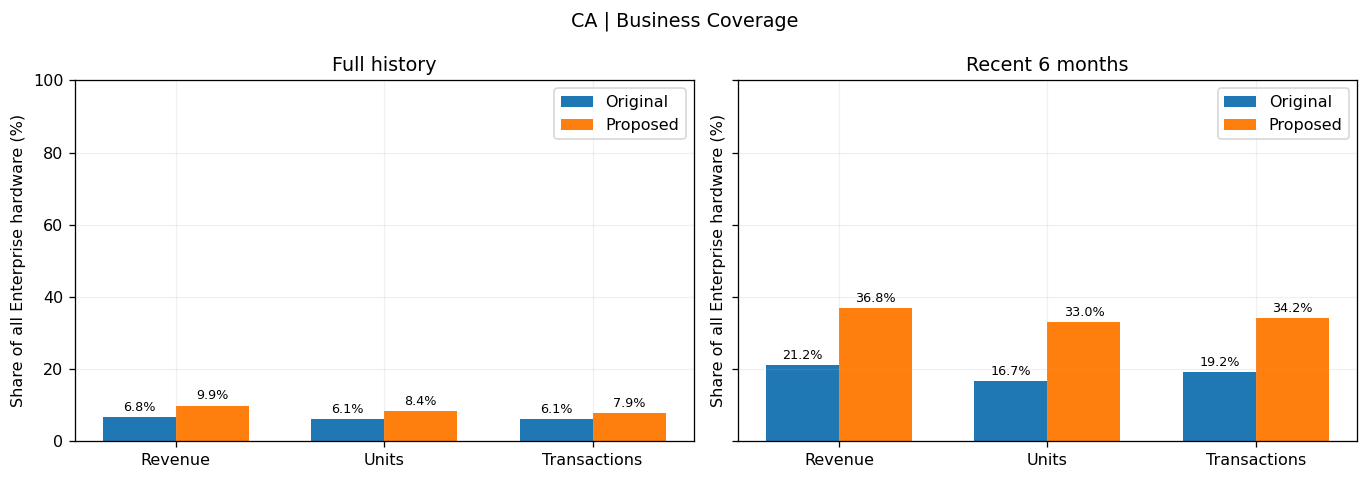

In [20]:
def calculate_coverage(df, window):
    totals=df[['revenue','units','tx']].sum()
    rows=[]
    for label,keys in [('Original',orig_keys),('Proposed',new_keys)]:
        sel=df.loc[df[label],['revenue','units','tx']].sum()
        rows.append({'window':window,'selection':label,'products':len(keys),
                     **{f'{m}_pct':100*sel[m]/totals[m] if totals[m]>0 else np.nan for m in ['revenue','units','tx']}})
    return pd.DataFrame(rows)
coverage=pd.concat([calculate_coverage(full_history,'Full history'),calculate_coverage(recent,'Recent 6 months')],ignore_index=True)
display(coverage.round(2))
fig,axs=plt.subplots(1,2,figsize=(12,4.2),sharey=True)
for ax,(window,rows) in zip(axs,coverage.groupby('window',sort=False)):
    x=np.arange(3)
    for i,(_,r) in enumerate(rows.iterrows()):
        bars=ax.bar(x+(i-.5)*.35,[r['revenue_pct'],r['units_pct'],r['tx_pct']],width=.35,label=r['selection'])
        ax.bar_label(bars,fmt='%.1f%%',fontsize=8,padding=2)
    ax.set_xticks(x,['Revenue','Units','Transactions'])
    ax.set_title(window);ax.set_ylabel('Share of all Enterprise hardware (%)');ax.legend()
axs[0].set_ylim(0,max(100,coverage[['revenue_pct','units_pct','tx_pct']].max().max()*1.18))
fig.suptitle(f'{MARKET} | Business Coverage');fig.tight_layout();fig.savefig(OUT/'01_coverage.png',dpi=180,bbox_inches='tight');plt.show()
coverage.to_csv(OUT/'coverage_summary.csv',index=False)

## 3 | Monthly revenue and units — complete history

Each line is the **actual monthly value** (not an index). Recent six months are shaded. The selected lines may be lower because they contain fewer products. Compare movements over time and report the coverage percentage above.

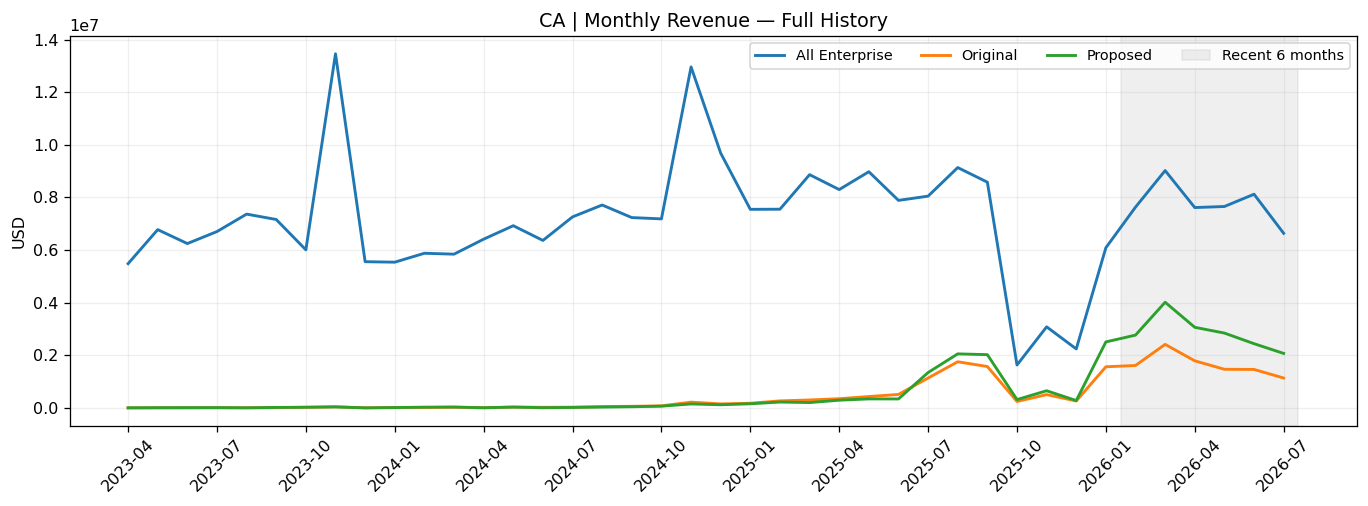

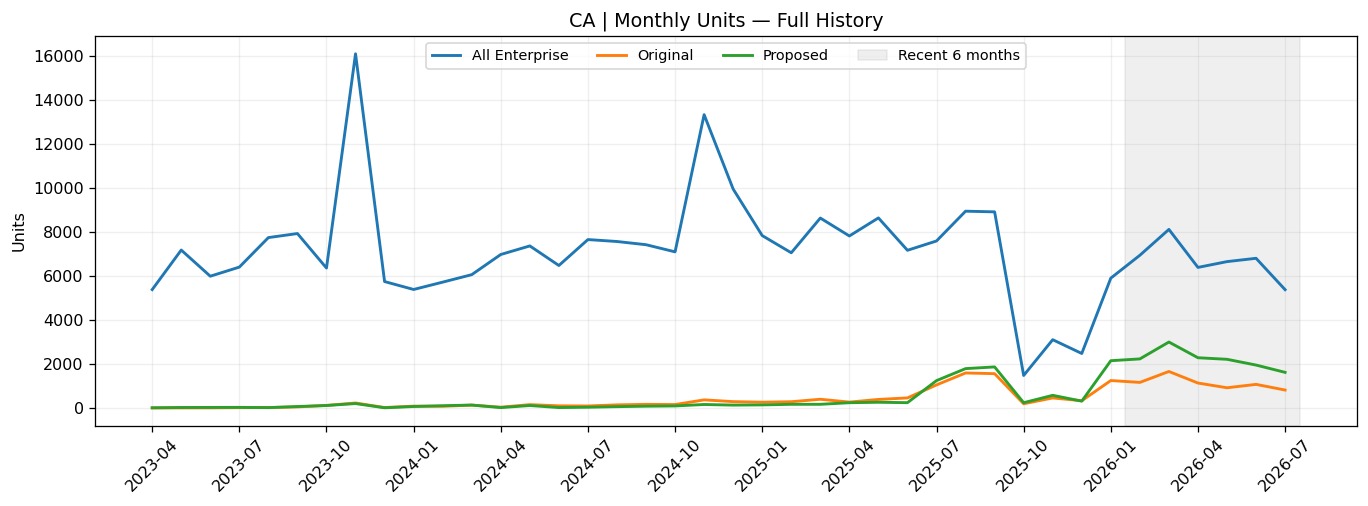

In [21]:
def monthly_trend(metric, filename):
    calendar=pd.period_range(all_history_months[0],all_history_months[-1],freq='M').astype(str).tolist()
    fig,ax=plt.subplots(figsize=(12,4.5))
    for label in ['All Enterprise','Original','Proposed']:
        subset=full_history if label=='All Enterprise' else full_history.loc[full_history[label]]
        y=subset.groupby('month')[metric].sum().reindex(calendar,fill_value=0)
        ax.plot(np.arange(len(calendar)),y.values,linewidth=1.8,label=label)
    ax.axvspan(len(calendar)-RECENT_MONTHS-.5,len(calendar)-.5,alpha=.12,color='gray',label='Recent 6 months')
    step=max(1,len(calendar)//12)
    ax.set_xticks(np.arange(0,len(calendar),step),calendar[::step],rotation=45)
    ax.set_title(f'{MARKET} | Monthly {metric.title()} — Full History')
    ax.set_ylabel('USD' if metric=='revenue' else 'Units')
    ax.legend(ncol=4,fontsize=9);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(OUT/filename,dpi=180,bbox_inches='tight');plt.show()
monthly_trend('revenue','02_revenue_trend.png')
monthly_trend('units','03_units_trend.png')

## 4 | Recent 12-month revenue trends by product type

Simple monthly revenue lines for Notebook, Workstation, Desktop and Visuals. These help check whether important categories have similar recent sales movements; they do not require identical dollar amounts.

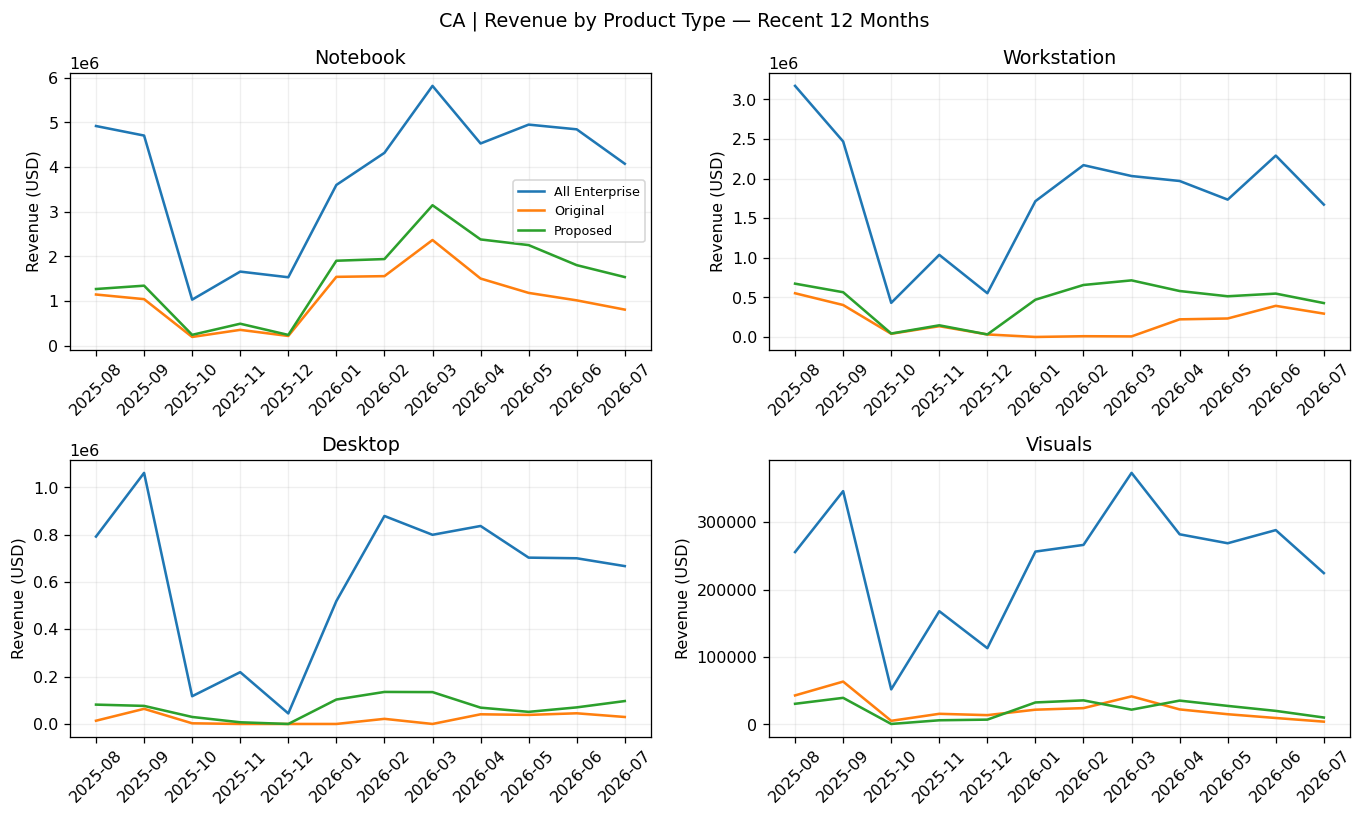

In [22]:
fig,axs=plt.subplots(2,2,figsize=(12,7.2))
months=midterm_months
for ax,typ in zip(axs.flat,TYPES):
    base=midterm.loc[midterm.product_type.eq(typ)]
    for label in ['All Enterprise','Original','Proposed']:
        sub=base if label=='All Enterprise' else base.loc[base[label]]
        line=sub.groupby('month').revenue.sum().reindex(months,fill_value=0)
        ax.plot(months,line.values,label=label,linewidth=1.6)
    ax.set_title(typ.title());ax.set_ylabel('Revenue (USD)');ax.tick_params(axis='x',rotation=45);ax.grid(alpha=.2)
axs[0,0].legend(fontsize=8)
fig.suptitle(f'{MARKET} | Revenue by Product Type — Recent 12 Months')
fig.tight_layout();fig.savefig(OUT/'04_revenue_by_type.png',dpi=180,bbox_inches='tight');plt.show()

## 5 | ASP trends by product type — recent 12 months

ASP = total revenue / total units within each type and month. Unlike an indexed chart, this shows **actual selling price in USD per unit**. Gaps indicate months without valid units.

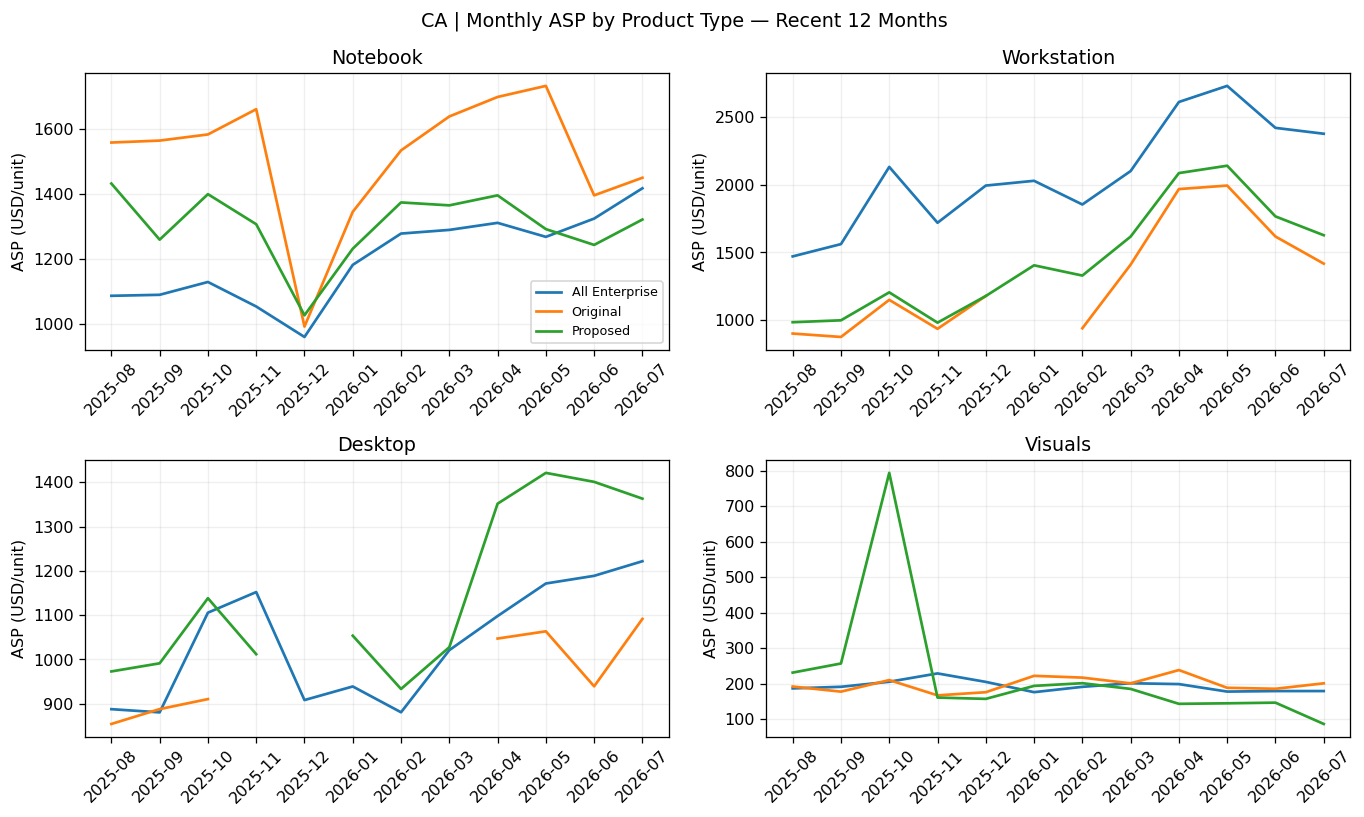

In [23]:
fig,axs=plt.subplots(2,2,figsize=(12,7.2))
for ax,typ in zip(axs.flat,TYPES):
    base=midterm.loc[midterm.product_type.eq(typ)]
    for label in ['All Enterprise','Original','Proposed']:
        sub=base if label=='All Enterprise' else base.loc[base[label]]
        sums=sub.groupby('month')[['revenue','units']].sum().reindex(months,fill_value=0)
        asp=sums.revenue/sums.units.replace(0,np.nan)
        ax.plot(months,asp.values,label=label,linewidth=1.7)
    ax.set_title(typ.title());ax.set_ylabel('ASP (USD/unit)');ax.tick_params(axis='x',rotation=45);ax.grid(alpha=.2)
axs[0,0].legend(fontsize=8)
fig.suptitle(f'{MARKET} | Monthly ASP by Product Type — Recent 12 Months')
fig.tight_layout();fig.savefig(OUT/'05_asp_by_type.png',dpi=180,bbox_inches='tight');plt.show()

## 6 | Baseline readiness: usable historical weeks

Check weekly sample availability using a 90-day historical lookback, at least five rows in the past 30 days, positive past 90-day activity, and at least two transactions with positive revenue and units in the next 7 days. Reference: at least 9 recent usable weeks and 7 earlier usable weeks. **For Canada, these are diagnostic US-reference thresholds, not approved Canadian rules.**

Original: 24 groups; rule pass 13 / 24; median recent usable weeks = 14.5; median historical usable weeks = 15.5
Proposed: 38 groups; rule pass 11 / 38; median recent usable weeks = 15.0; median historical usable weeks = 6.0


,selection,products,passing_reference_rule,median_recent_usable_weeks,median_historical_usable_weeks
0,Original,24,13,14.5,15.5
1,Proposed,38,11,15.0,6.0


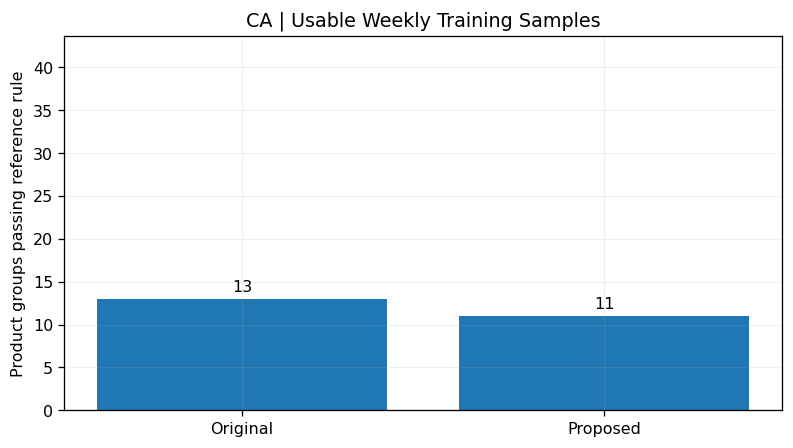

Passing a weekly sample screen does not prove generalization; test future periods and held-out product groups.


In [24]:
# Weekly checkpoints computed from the daily Enterprise transactions of listed product groups.
end_day = pd.Period(end_month,freq='M').end_time.normalize()
recent_start = end_day - pd.Timedelta(weeks=26) + pd.Timedelta(days=1)
weekly_rows=[]
cohort_keys = orig_keys | new_keys
for group_key, dg in daily_product.groupby(KEY,sort=False):
    if group_key not in cohort_keys: continue
    dg=dg.sort_values('day')
    first=pd.Timestamp(dg.day.min()).normalize()
    start=first + pd.Timedelta(days=90)
    # Same weekday, seven-day spacing. No extrapolation beyond available global data.
    checkpoints=pd.date_range(start=start,end=end_day-pd.Timedelta(days=7),freq='7D')
    if len(checkpoints)==0:
        weekly_rows.append({'group_key':group_key,'recent_usable':0,'recent_checkpoints':0,'historical_usable':0,'historical_checkpoints':0})
        continue
    days=pd.DatetimeIndex(dg.day)
    transactions=dg.tx.to_numpy(dtype=float)
    rev=dg.revenue.to_numpy(dtype=float)
    units=dg.units.to_numpy(dtype=float)
    c_tx=np.r_[0,transactions.cumsum()]
    c_rev=np.r_[0,rev.cumsum()]
    c_units=np.r_[0,units.cumsum()]
    # Count within [a,b] using index boundaries on observed days.
    def interval(c,a,b):
        left=days.searchsorted(a,'left'); right=days.searchsorted(b,'right')
        return c[right]-c[left]
    rt=rc=ht=hc=0
    for t in checkpoints:
        n30=interval(c_tx,t-pd.Timedelta(days=30),t-pd.Timedelta(days=1))
        n90=interval(c_tx,t-pd.Timedelta(days=90),t-pd.Timedelta(days=1))
        next_tx=interval(c_tx,t+pd.Timedelta(days=1),t+pd.Timedelta(days=7))
        next_rev=interval(c_rev,t+pd.Timedelta(days=1),t+pd.Timedelta(days=7))
        next_units=interval(c_units,t+pd.Timedelta(days=1),t+pd.Timedelta(days=7))
        usable=bool((n30>=5) and (n90>0) and (next_tx>=2) and (next_rev>0) and (next_units>0))
        if t>=recent_start:
            rc+=1;rt+=usable
        else:
            hc+=1;ht+=usable
    weekly_rows.append({'group_key':group_key,'recent_usable':rt,'recent_checkpoints':rc,'historical_usable':ht,'historical_checkpoints':hc})
weekly=pd.DataFrame(weekly_rows)
weekly['Original']=weekly.group_key.isin(orig_keys)
weekly['Proposed']=weekly.group_key.isin(new_keys)
weekly['recent_coverage_pct']=np.where(weekly.recent_checkpoints>0,100*weekly.recent_usable/weekly.recent_checkpoints,np.nan)
weekly['pass_reference_rule']=(weekly.recent_usable>=MIN_RECENT_USABLE_WEEKS)&(weekly.historical_usable>=MIN_HISTORICAL_USABLE_WEEKS)
for label in ['Original','Proposed']:
    q=weekly.loc[weekly[label]]
    print(f'{label}: {len(q)} groups; rule pass {q.pass_reference_rule.sum()} / {len(q)}; '
          f'median recent usable weeks = {q.recent_usable.median()}; median historical usable weeks = {q.historical_usable.median()}')
weekly['product_name']=weekly.group_key.map(lambda x:x[0]);weekly['product_family']=weekly.group_key.map(lambda x:x[1]);weekly['product_type']=weekly.group_key.map(lambda x:x[2])
weekly.drop(columns='group_key').to_csv(OUT/'baseline_weekly_product_audit.csv',index=False)

summary=[]
for label in ['Original','Proposed']:
    q=weekly.loc[weekly[label]]
    summary.append({'selection':label,'products':len(q),'passing_reference_rule':int(q.pass_reference_rule.sum()),
                    'median_recent_usable_weeks':q.recent_usable.median(),
                    'median_historical_usable_weeks':q.historical_usable.median()})
readiness=pd.DataFrame(summary)
display(readiness)
fig,ax=plt.subplots(figsize=(7,4))
bars=ax.bar(readiness.selection,readiness.passing_reference_rule)
ax.bar_label(bars,padding=3)
ax.set_ylabel('Product groups passing reference rule')
ax.set_title(f'{MARKET} | Usable Weekly Training Samples')
ax.set_ylim(0,max(readiness.products.max(),1)*1.15)
fig.tight_layout();fig.savefig(OUT/'06_baseline_readiness.png',dpi=180,bbox_inches='tight');plt.show()
readiness.to_csv(OUT/'baseline_readiness_summary.csv',index=False)
print('Passing a weekly sample screen does not prove generalization; test future periods and held-out product groups.')